# Embryo-Sim · Stufe 1: Zygote → Blastozyste in der Zona pellucida (2D)

**Frage:** Reichen wenige lokale Regeln (Teilung, Mechanik, "wie frei ist meine Oberfläche?", Blastozoel, Zona-Abbau), damit aus einer Zygote eine Blastozyste mit äußerem Trophoblast, innerem Embryoblast und flüssigkeitsgefüllter Höhle entsteht, die die Zona an *einer* Stelle öffnet? Und wie robust ist das gegen Störungen?

**Regeln im Modell**
1. Zellen sind weiche Kreise mit Abstoßung und kurzreichweitiger Adhäsion.
2. Teilung nach individueller Zykluszeit; in der Furchung ohne Wachstum (Tochterzellen kleiner).
3. Ab 8 Zellen (Kompaktion): freie Oberfläche → Trophoblast (TE), umringt → Embryoblast (ICM).
4. Bis `lock_n` Zellen ist das Schicksal plastisch (folgt der Position), danach endgültig.
5. TE teilt sich tangential zur Oberfläche (Epithel).
6. **Blastozoel:** Nach dem Lock-in entsteht eine Flüssigkeitsscheibe. Die TE-Zellen pumpen Flüssigkeit hinein (Fläche wächst), die Scheibe drückt alle Zellen weg und kann sich selbst verschieben (so landet der Embryoblast an einem Pol). Sie wächst nur, solange der Zellring ihren Rand **abdichtet**, sonst läuft sie aus und kollabiert.
7. **Zona pellucida:** Ring aus 72 Segmenten. Jedes Segment verliert Festigkeit durch (a) **lytische Enzyme** der TE-Zellen im Wandkontakt und (b) **mechanischen Druck** der Zellen auf die Wand. Dünne Stellen werden stärker belastet (Rückkopplung), die schwächste Stelle bricht zuerst durch.

**Skala:** 2D-**Äquatorialschnitt**. Zellzahlen sind 2D-Äquivalente (ein Schnitt zeigt nur einen Bruchteil der Zellen einer echten Blastozyste). Zeit in "Stunden" ist nur grob kalibriert. Parameter stehen in `Params` (`src/simulation.py`).

**Bekannte Grenzen:** Das Modell hat keine Zell-Zell-Verbindungen (Tight Junctions), die den TE-Ring als Verband zusammenhalten. Nach dem Aufgehen der Zona **zerfällt der Ring** deshalb, die Höhle kollabiert. Das echte Ausschlüpfen ist damit *nicht* abgebildet, nur die Öffnung und der Beginn des Austritts. Außerdem ist die Gewichtung von Enzymen und Druck eine **Modellannahme** (siehe Abschnitt 4, die Literatur ist hier nicht einig).

In [1]:
%load_ext autoreload
%autoreload 2

import sys, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Projektwurzel finden (egal ob Notebook-Ordner oder Projektordner das Arbeitsverzeichnis ist)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
(ROOT / "results").mkdir(exist_ok=True)

from simulation import Simulation, Params, UNDECIDED, TE, ICM
import viz

plt.rcParams["figure.dpi"] = 110

## 1 · Entwicklung im Zeitraffer

Grau = unentschieden, blau = Trophoblast, orange = Embryoblast, hellblaue Scheibe = Blastozoel, goldener Ring = Zona (dünnt aus und öffnet sich an einer Stelle). Mit anderem `seed` ändert sich der Zufall (Teilungsrichtung, Zykluszeiten, Zona-Inhomogenität), nicht die Regeln.

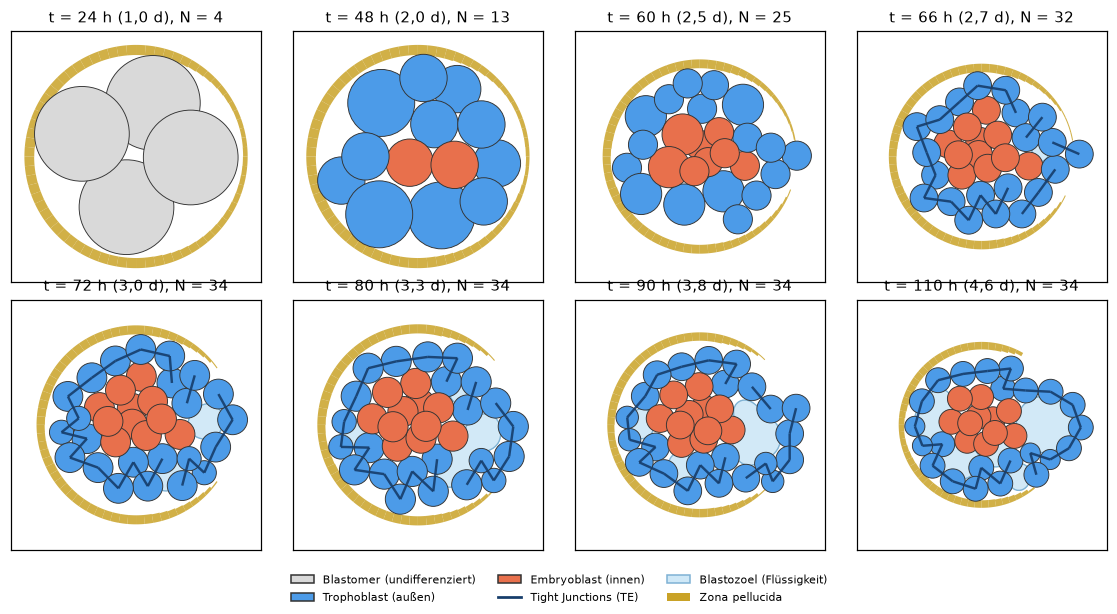

t = 110.0 h | N =  34 | undiff. 0, TE 23, ICM 11 | TJ: 22 | Blastozoel: R=0.77 (43 P.) | Zona: offen seit 51 h, 3 Zellen draußen


In [2]:
sim = Simulation(seed=8)
fig = viz.timeline(sim, times=[24, 48, 60, 66, 72, 80, 90, 110])
plt.show()
print(sim.summary())

## 2 · Virtuelles Experiment A: Driesch-Halbembryo

Im 2-Zell-Stadium wird eine Blastomere entfernt. Kontrolle und Experiment starten aus **exakt demselben Zustand** (gleicher Zufallsgenerator), Unterschiede stammen also nur von der Störung.

**Beobachten:** Bildet das Halbembryo trotzdem beide Schicksale und eine Höhle? Wie viel später? (Achtung: Lock-in und Kavitation sind im Modell an *Zellzahlen* gekoppelt, das Halbembryo muss also eine Teilung nachholen. Ist das eine gute Annahme?)

Kontrolle:  t =  72.0 h | N =  33 | undiff. 0, TE 23, ICM 10 | TJ: 21 | Blastozoel: R=0.59 (25 P.) | Zona: intakt
Halbembryo: t =  72.0 h | N =  19 | undiff. 1, TE 14, ICM 4 | Zona: intakt


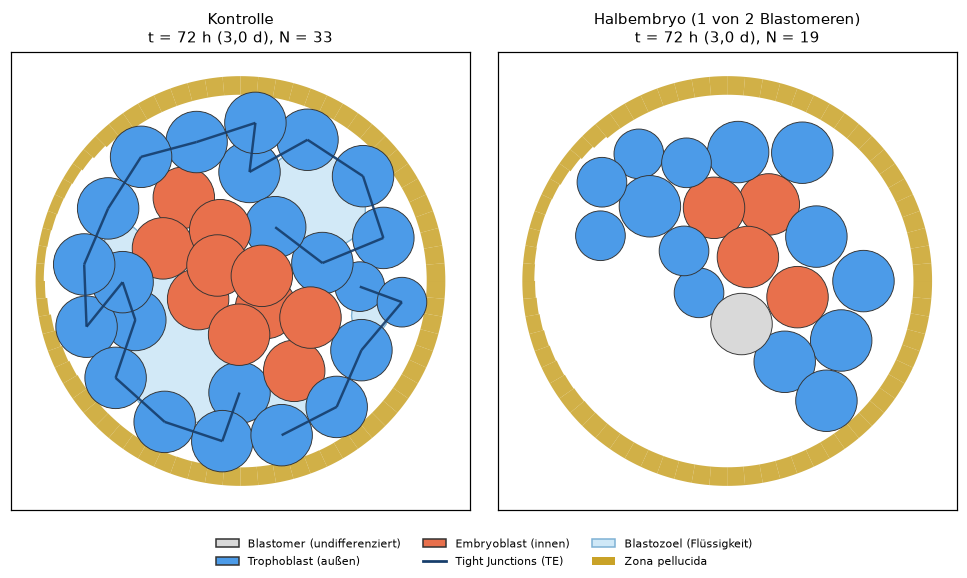

Kavitation: Kontrolle 63.5 h, Halbembryo 75.1 h (Verzögerung 11.6 h, 6 Seeds)


In [7]:
sim = Simulation(seed=2)
sim.run_until_n(2)                      # 2-Zell-Stadium
control, half = copy.deepcopy(sim), copy.deepcopy(sim)
half.remove_cells(np.arange(half.n) == 0)   # eine Blastomere entfernen

for s in (control, half):
    s.run(72 - s.t)

print("Kontrolle: ", control.summary())
print("Halbembryo:", half.summary())
viz.compare([control, half], ["Kontrolle", "Halbembryo (1 von 2 Blastomeren)"])
plt.show()

# Zeitpunkt der Kavitation über mehrere Seeds
def run_to_cavity(s, t_max=200):
    while s.t_cavity is None and s.t < t_max:
        s.step()
    return s.t_cavity

times = []
for sd in range(6):
    s0 = Simulation(seed=sd); s0.run_until_n(2)
    c, h = copy.deepcopy(s0), copy.deepcopy(s0)
    h.remove_cells(np.arange(h.n) == 0)
    times.append((run_to_cavity(c), run_to_cavity(h)))
times = np.array(times)
print(f"Kavitation: Kontrolle {times[:,0].mean():.1f} h, Halbembryo {times[:,1].mean():.1f} h (Verzögerung {np.mean(times[:,1]-times[:,0]):.1f} h, 6 Seeds)")

## 3 · Virtuelles Experiment B: Alle ICM-Zellen entfernen, vor vs. nach Lock-in

**Hypothese:** Solange Schicksale plastisch sind (vor `lock_n`), kann der Embryo einen neuen Embryoblast bilden, weil Zellen, die nach innen geraten, ICM werden. Nach dem Lock-in nicht mehr. (Qualitative Analogie zum Konzept "Regulationsfähigkeit endet mit der Determination", keine quantitative Vorhersage.)

vor Lock-in: direkt nach Ablation {'Blastomer (undifferenziert)': 0, 'Trophoblast (außen)': 15, 'Embryoblast (innen)': 0}
vor Lock-in: 40 h später          {'Blastomer (undifferenziert)': 0, 'Trophoblast (außen)': 28, 'Embryoblast (innen)': 6}


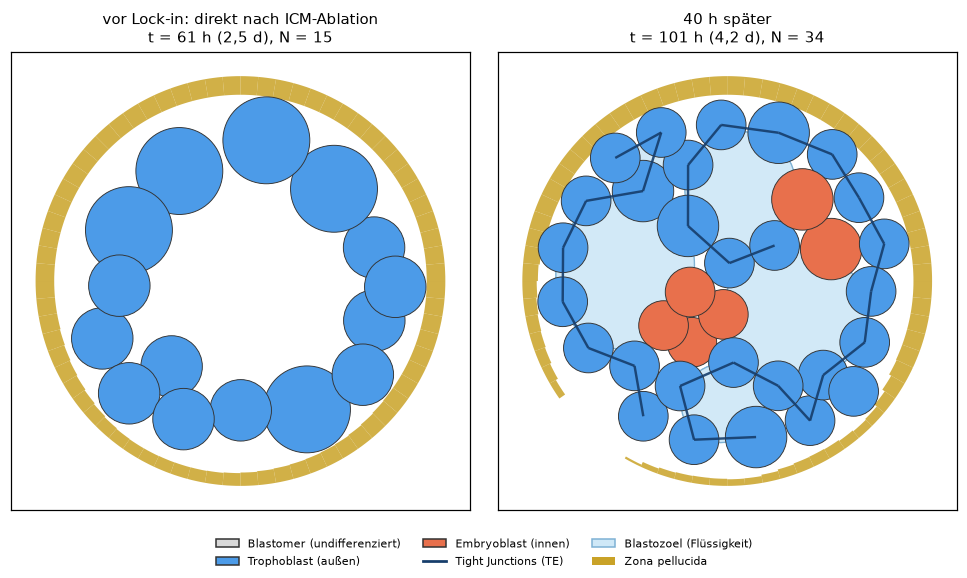

nach Lock-in: direkt nach Ablation {'Blastomer (undifferenziert)': 0, 'Trophoblast (außen)': 21, 'Embryoblast (innen)': 0}
nach Lock-in: 40 h später          {'Blastomer (undifferenziert)': 0, 'Trophoblast (außen)': 34, 'Embryoblast (innen)': 0}


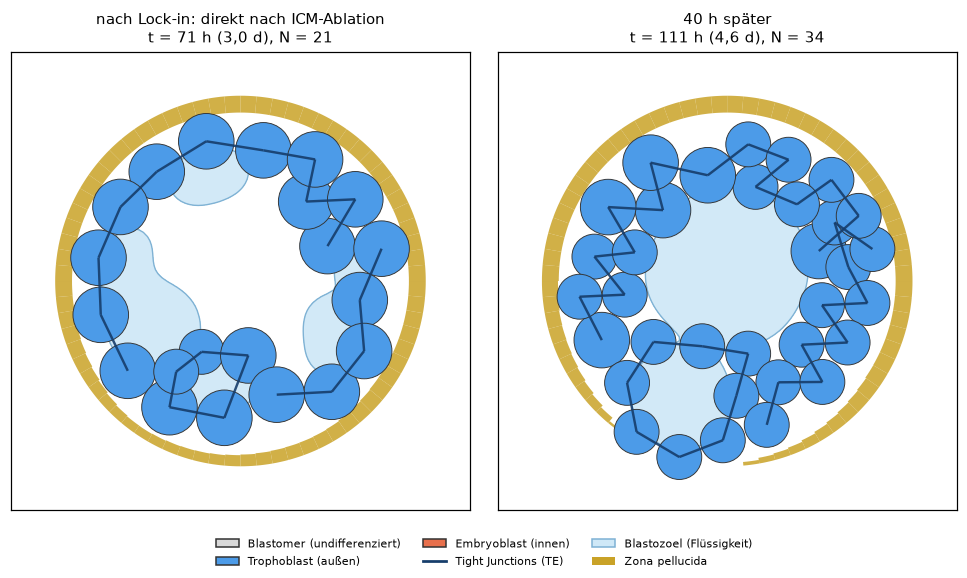

In [ ]:
def ablate_icm(n_stage, seed=0, observe=40):
    s = Simulation(seed=seed)
    s.run_until_n(n_stage)
    stage = "nach Lock-in" if s.locked else "vor Lock-in"
    s.remove_cells(s.fate == ICM)
    right_after = copy.deepcopy(s)
    s.run(observe)
    return stage, right_after, s

for n_stage in (22, 34):
    stage, before, after = ablate_icm(n_stage)
    print(f"{stage}: direkt nach Ablation {before.counts()}")
    print(f"{stage}: 40 h später          {after.counts()}")
    viz.compare([before, after], [f"{stage}: direkt nach ICM-Ablation", "40 h später"])
    plt.show()

# Wie robust ist das? 8 Seeds je Zeitpunkt
for n_stage in (22, 34):
    icm_after = [ablate_icm(n_stage, seed=sd)[2].counts()["Embryoblast (innen)"] for sd in range(8)]
    print(f"Start bei N={n_stage}: ICM-Zellen 40 h nach der Ablation in 8 Läufen: {icm_after}")

## 4 · Virtuelles Experiment C: Was öffnet die Zona, Druck oder Enzyme?

Gemessen wird die **Zeit bis zur ersten Öffnung**. Die Literatur ist hier nicht einig: Eine Studie an Mausblastozysten fand, dass ein reduzierter Höhlendruck die Schlüpfwahrscheinlichkeit senkt (Leonavicius et al., PNAS 2018). Eine andere schloss, dass Schlüpfen überwiegend durch Zona-Lyse und nicht durch Druck zustande kommt. Das Modell kann beide Hypothesen als **Parametersatz** abbilden:

* **Druck-dominant** (Standard): `zp_enzyme = 0.01`, `zp_stress = 0.50`
* **Enzym-dominant:** `zp_enzyme = 0.06`, `zp_stress = 0.03`

Bedingungen: **Kontrolle**, **Pumpe gehemmt** (Na/K-ATPase-Hemmung → kein Höhlendruck), **Protease gehemmt**, **Zona-Härtung ×2** und **Laser-Loch** (Assisted Hatching), beide bei t = 40 h.

**Fragen:** Welche Hypothese sagt bei Pumpenhemmung eine starke Verzögerung vorher, welche bei Proteasehemmung? Welches Experiment würdest du im Labor machen, um zwischen beiden zu unterscheiden? (Laufzeit ca. 1 Minute.)

--- Druck-dominant
Kontrolle          erste Öffnung nach  74.8 h | nie geöffnet (bis 200 h): 0/5
Pumpe gehemmt      erste Öffnung nach  97.9 h | nie geöffnet (bis 200 h): 1/5
Protease gehemmt   erste Öffnung nach  76.4 h | nie geöffnet (bis 200 h): 0/5
Zona-Härtung x2    erste Öffnung nach  84.5 h | nie geöffnet (bis 200 h): 0/5
Laser-Loch         erste Öffnung nach  40.0 h | nie geöffnet (bis 200 h): 0/5
--- Enzym-dominant
Kontrolle          erste Öffnung nach  68.0 h | nie geöffnet (bis 200 h): 0/5
Pumpe gehemmt      erste Öffnung nach  74.1 h | nie geöffnet (bis 200 h): 0/5
Protease gehemmt   erste Öffnung nach  93.9 h | nie geöffnet (bis 200 h): 0/5
Zona-Härtung x2    erste Öffnung nach  89.1 h | nie geöffnet (bis 200 h): 0/5
Laser-Loch         erste Öffnung nach  40.0 h | nie geöffnet (bis 200 h): 0/5


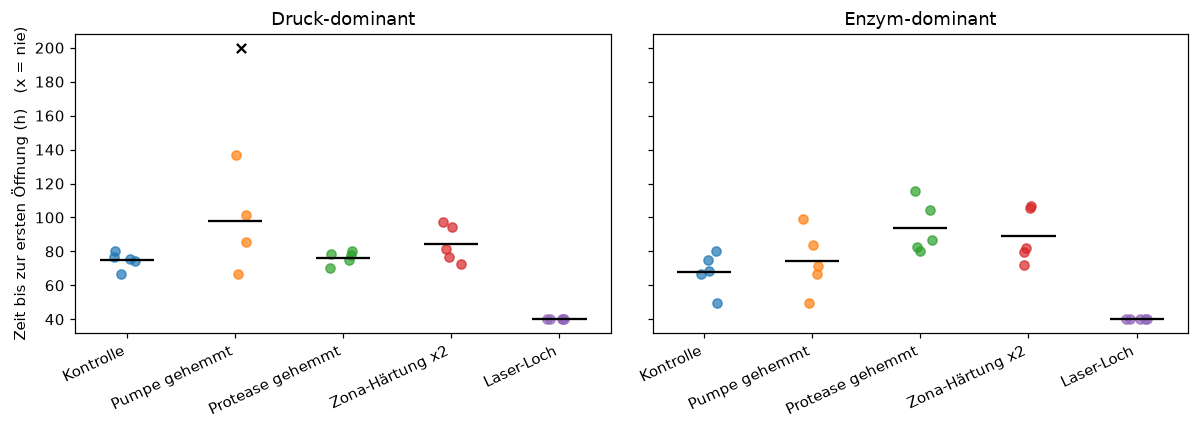

In [ ]:
HYPOTHESES = {
    "Druck-dominant": dict(zp_enzyme=0.01, zp_stress=0.50),
    "Enzym-dominant": dict(zp_enzyme=0.06, zp_stress=0.03),
}
CONDITIONS = ["Kontrolle", "Pumpe gehemmt", "Protease gehemmt", "Zona-Härtung x2", "Laser-Loch"]
T_MAX = 200

def time_to_open(params, condition, seed):
    s = Simulation(Params(**params), seed=seed)
    if condition == "Pumpe gehemmt":
        s.p.lumen_pump = 0.0
    elif condition == "Protease gehemmt":
        s.p.zp_enzyme = 0.0
    elif condition == "Zona-Härtung x2":
        s.run(40); s.harden_zp(2.0)
    elif condition == "Laser-Loch":
        s.run(40); s.drill_zp(angle_deg=0, width_deg=20)
    while not s.hatched and s.t < T_MAX:
        s.step()
    return s.t_hatch if s.hatched else np.nan

seeds = range(5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
rng = np.random.default_rng(0)
for ax, (hname, params) in zip(axes, HYPOTHESES.items()):
    print(f"--- {hname}")
    for k, c in enumerate(CONDITIONS):
        t = np.array([time_to_open(params, c, sd) for sd in seeds])
        opened = ~np.isnan(t)
        x = k + rng.uniform(-0.12, 0.12, len(t))
        ax.scatter(x[opened], t[opened], alpha=0.7)
        ax.scatter(x[~opened], np.full((~opened).sum(), T_MAX), marker="x", color="k")
        ax.hlines(np.nanmean(t) if opened.any() else T_MAX, k - 0.25, k + 0.25, color="k")
        print(f"{c:18s} erste Öffnung nach {np.nanmean(t) if opened.any() else float('nan'):5.1f} h | nie geöffnet (bis {T_MAX} h): {(~opened).sum()}/{len(t)}")
    ax.set_title(hname)
    ax.set_xticks(range(len(CONDITIONS)), CONDITIONS, rotation=25, ha="right")
axes[0].set_ylabel("Zeit bis zur ersten Öffnung (h)   (x = nie)")
plt.tight_layout(); plt.show()

## 5 · Interaktiv: Zeit laufen lassen und Störungen einbringen

* **Kontrolle:** Bei der ersten Störung wird automatisch eine ungestörte Kopie angelegt und läuft parallel mit (links Kontrolle, rechts gestört).
* Slider ändern Parameter **nur im gestörten Embryo**, wirken also ab dem nächsten "Weiter".
* Neustart mit anderem Seed über *Reset*.

In [ ]:
import ipywidgets as w
from IPython.display import display, clear_output

state = {"sim": Simulation(seed=1), "control": None}
out = w.Output()
info = w.HTML()


def ensure_control():
    if state["control"] is None:
        state["control"] = copy.deepcopy(state["sim"])


def redraw():
    sim, ctrl = state["sim"], state["control"]
    with out:
        clear_output(wait=True)
        if ctrl is None:
            fig, ax = plt.subplots(figsize=(5.5, 5.8))
            viz.draw(sim, ax=ax)
        else:
            fig = viz.compare([ctrl, sim], ["Kontrolle", "Gestört"], size=4.2)
        plt.show()
        plt.close(fig)
    info.value = f"<code>{sim.summary()} | locked = {sim.locked}</code>"


def advance(hours):
    def _cb(_):
        state["sim"].run(hours)
        if state["control"] is not None:
            state["control"].run(hours)
        redraw()
    return _cb


def perturb(action):
    def _cb(_):
        ensure_control()
        action(state["sim"])
        redraw()
    return _cb


def reset(_=None):
    state["sim"] = Simulation(seed=seed_box.value)
    state["control"] = None
    # Slider-Werte auf den neuen Embryo übertragen
    p = state["sim"].p
    p.outer_threshold, p.lock_n, p.te_planar_division = thr.value, lock.value, planar.value
    redraw()


def btn(text, cb, style=""):
    b = w.Button(description=text, button_style=style, layout=w.Layout(width="auto"))
    b.on_click(cb)
    return b


# --- Parameter-Slider (wirken auf den gestörten Embryo)
thr = w.FloatSlider(value=0.45, min=0.25, max=0.8, step=0.05, description="TE-Schwelle", continuous_update=False)
lock = w.IntSlider(value=28, min=8, max=34, step=2, description="Lock-in bei N", continuous_update=False)
planar = w.Checkbox(value=True, description="TE teilt sich planar")
seed_box = w.IntText(value=1, description="Seed", layout=w.Layout(width="150px"))


def on_param(change):
    ensure_control()
    p = state["sim"].p
    p.outer_threshold, p.lock_n, p.te_planar_division = thr.value, lock.value, planar.value


for widget in (thr, lock, planar):
    widget.observe(on_param, names="value")

controls = w.VBox([
    w.HBox([btn("+6 h", advance(6), "primary"), btn("+24 h", advance(24), "primary"), btn("Reset", reset, "warning"), seed_box]),
    w.HBox([
        btn("25 % Zufallszellen entfernen", perturb(lambda s: s.remove_random(int(0.25 * s.n)))),
        btn("Halbieren", perturb(lambda s: s.remove_half())),
        btn("Alle ICM entfernen", perturb(lambda s: s.remove_cells(s.fate == ICM))),
        btn("Alle TE entfernen", perturb(lambda s: s.remove_cells(s.fate == TE))),
    ]),
    w.HBox([
        btn("Zona: Laser-Loch", perturb(lambda s: s.drill_zp(angle_deg=0, width_deg=20))),
        btn("Zona härten x2", perturb(lambda s: s.harden_zp(2.0))),
        btn("Protease hemmen", perturb(lambda s: setattr(s.p, "zp_enzyme", 0.0))),
        btn("Pumpe hemmen", perturb(lambda s: setattr(s.p, "lumen_pump", 0.0))),
        btn("Blastozoel kollabieren", perturb(lambda s: s.collapse_lumen(1.0))),
    ]),
    w.HBox([thr, lock, planar]),
])
display(controls, info, out)
redraw()

HTML(value='')

Output()

## 6 · Film speichern (GIF, ohne ffmpeg)

In [1]:
sim = Simulation(seed=8)
frames = viz.record(sim, hours=120, every=1.0)
gif = viz.make_gif(frames, ROOT / "results" / "stufe1_blastozyste.gif", fps=15)
print("gespeichert:", gif)

from IPython.display import Image
Image(filename=str(gif))

NameError: name 'Simulation' is not defined

## Aufgaben zum Weiterdenken

1. **Schwelle:** Wie verändert sich der ICM-Anteil, wenn die TE-Schwelle (`outer_threshold`) von 0,45 auf 0,3 bzw. 0,6 geändert wird? Warum?
2. **Planare Teilung aus:** Was passiert mit der Dicke der TE-Schicht und mit der Höhle?
3. **Lock-in-Zeitpunkt:** Wie vollständig ist die ICM-Regeneration bei verschiedenem `lock_n` und Startzeitpunkt? Warum klappt sie nicht in jedem Lauf?
4. **Hypothesenvergleich:** Eine Studie fand, dass Zona-*Ausdünnung* ein Schlüpfdefizit korrigierte, was zur Enzym-Hypothese passt. Eine andere fand, dass reduzierter Druck das Schlüpfen verringert. Welche der beiden Modell-Varianten erklärt beides? Wie müsste man `zp_enzyme` und `zp_stress` wählen? Ist die Annahme "beides wirkt additiv" sinnvoll?
5. **Abdichtung:** Setze `lumen_seal_min` auf 0,5. Was passiert mit dem Zellring und warum ist das physiologisch unplausibel?
6. **Zerfall nach dem Öffnen:** Warum zerfällt der Zellring, sobald die Zona offen ist? Welche biologische Struktur fehlt im Modell (Tipp: Zell-Zell-Verbindungen im Epithel), und wie würdest du sie einbauen?
7. **Zellzahl-Kopplung:** Lock-in und Kavitation hängen an der Zellzahl. Wie würdest du stattdessen Zeit oder Größe verwenden, und was änderte das beim Halbembryo?
8. **Zufall vs. Regel:** Wie stark streuen Kavitations- und Öffnungszeit über 20 Seeds? Was erzeugt die Streuung?